<a href="https://colab.research.google.com/github/raymondtyaba/case-manager-dashboard/blob/main/build_practitioner_ready_chart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practitioner-Ready Chart
Upload `analysis_ready_dataset.csv` when prompted, then run every cell in order.

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from google.colab import files
from pathlib import Path
print("Libraries are ready")

Libraries are ready


## Upload and load the analysis-ready dataset

In [8]:
uploaded = files.upload()
csv_files = list(Path('/content').glob('*.csv'))
if not csv_files:
    raise FileNotFoundError("No CSV file found. Upload analysis_ready_dataset.csv and rerun this cell.")
preferred = [p for p in csv_files if p.name == 'analysis_ready_dataset.csv']
file_path = preferred[0] if preferred else csv_files[0]
df = pd.read_csv(file_path)
print(f"Loaded: {file_path.name}")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Saving analysis_ready_dataset.csv to analysis_ready_dataset (1).csv
Loaded: analysis_ready_dataset.csv
Shape: (2957, 5)
Columns: ['LocationID', 'LocationName', 'StateAbbr', 'diagnosed_diabetes_prevalence', 'food_insecurity_prevalence']


## Confirm the variables and missing values

In [9]:
x_col = 'food_insecurity_prevalence'
y_col = 'diagnosed_diabetes_prevalence'
required = [x_col, y_col]
missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise KeyError("Missing required columns: " + ", ".join(missing_columns))
for c in required:
    df[c] = pd.to_numeric(df[c], errors='coerce')
print("Missing values before chart preparation:")
print(df[required].isnull().sum())
chart_df = df[required].dropna().copy()
rows_dropped = len(df) - len(chart_df)
if chart_df.empty:
    raise ValueError("No complete rows are available for the chart.")
print(f"Rows used in chart: {len(chart_df):,}")
print(f"Rows dropped for missing chart values: {rows_dropped:,}")

Missing values before chart preparation:
food_insecurity_prevalence       0
diagnosed_diabetes_prevalence    0
dtype: int64
Rows used in chart: 2,957
Rows dropped for missing chart values: 0


## Build and export the practitioner-ready chart

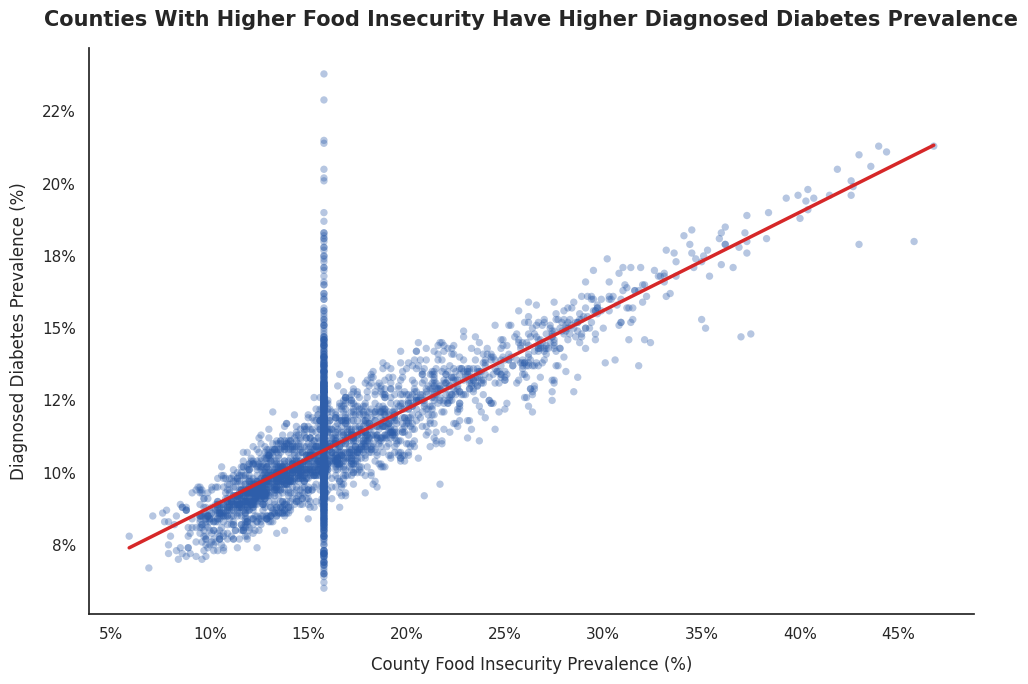

Saved: /content/food_insecurity_diabetes_chart.png


In [10]:
sns.set_theme(style='white')
fig, ax = plt.subplots(figsize=(10, 7))
sns.regplot(
    data=chart_df,
    x=x_col,
    y=y_col,
    ci=None,
    scatter_kws={'alpha': 0.35, 's': 28, 'color': '#2E5EAA', 'edgecolor': 'none'},
    line_kws={'color': '#D62728', 'linewidth': 2.5},
    ax=ax
)
ax.set_title(
    'Counties With Higher Food Insecurity Have Higher Diagnosed Diabetes Prevalence',
    fontsize=15,
    fontweight='bold',
    pad=16
)
ax.set_xlabel('County Food Insecurity Prevalence (%)', fontsize=12, labelpad=10)
ax.set_ylabel('Diagnosed Diabetes Prevalence (%)', fontsize=12, labelpad=10)
ax.grid(False)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
plt.tight_layout()
output_path = '/content/food_insecurity_diabetes_chart.png'
plt.savefig(output_path, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', output_path)

## Validate and download the PNG

In [11]:
from PIL import Image
image = Image.open('/content/food_insecurity_diabetes_chart.png')
print('PNG size:', image.size)
print('PNG format:', image.format)
if image.format != 'PNG':
    raise ValueError('The exported file is not a PNG.')
files.download('/content/food_insecurity_diabetes_chart.png')

PNG size: (1538, 1022)
PNG format: PNG


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>